# Optimización · Optimización continua

Métodos para minimizar funciones de una y varias variables: descenso por gradiente con paso fijo y con momento, el efecto del tamaño del paso, la búsqueda en línea por sección áurea, el método de Newton multivariante, mínimos cuadrados (lineales y no lineales) y problemas con restricciones mediante multiplicadores de Lagrange y condiciones KKT. Cada método escrito a mano se compara con `scipy.optimize` (`minimize`, `minimize_scalar`, `root`, `curve_fit`) o con `numpy.linalg`.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import optimize


def descenso(gradiente, x0, paso, momento=0.0, tol=1e-8, max_iter=20_000):
    """Descenso por gradiente con momento (bola pesada). Devuelve (x, iteraciones, trayectoria)."""
    x = np.array(x0, dtype=float)
    v = np.zeros_like(x)
    trayectoria = [x.copy()]
    for k in range(1, max_iter + 1):
        g = np.asarray(gradiente(x), dtype=float)
        if np.linalg.norm(g) < tol:
            return x, k - 1, np.array(trayectoria)
        v = momento * v - paso * g
        x = x + v
        trayectoria.append(x.copy())
        if not np.all(np.isfinite(x)) or np.linalg.norm(x) > 1e12:
            break
    return x, k, np.array(trayectoria)

## 1. Descenso por gradiente en una variable

Minimizar $f(x) = x^4 - 3x^3 + 2$ con descenso por gradiente de paso fijo $\eta = 0{,}01$, sabiendo que $f'(x) = 4x^3 - 9x^2$. Empezar en $x_0 = 4$ y comparar con el mínimo exacto ($f'(x) = 0 \Rightarrow x = 9/4$) y con `minimize_scalar`. Repetir empezando en $x_0 = -1$ y explicar por qué el método se queda cerca de $x = 0$.

In [2]:
f1 = lambda x: x**4 - 3 * x**3 + 2
df1 = lambda x: 4 * x**3 - 9 * x**2

x, iteraciones, _ = descenso(df1, [4.0], 0.01)
referencia = optimize.minimize_scalar(f1, bounds=(0, 5), method="bounded", options={"xatol": 1e-10})
print(f"Desde 4:  x = {x[0]:.8f} en {iteraciones} iteraciones; exacto 9/4 = {9 / 4}; minimize_scalar {referencia.x:.8f}")
assert math.isclose(x[0], 9 / 4, abs_tol=1e-7) and math.isclose(referencia.x, 9 / 4, abs_tol=1e-6)

x, iteraciones, _ = descenso(df1, [-1.0], 0.01, max_iter=2000)
print(f"Desde -1: x = {x[0]:.4f} tras {iteraciones} iteraciones, f'(x) = {df1(x[0]):.1e}")
print("x = 0 es un punto de inflexión con f'(0) = 0: el gradiente se anula y el paso se hace diminuto sin llegar a cruzarlo.")
assert -0.05 < x[0] < 0

Desde 4:  x = 2.25000000 en 92 iteraciones; exacto 9/4 = 2.25; minimize_scalar 2.25000000
Desde -1: x = -0.0054 tras 2000 iteraciones, f'(x) = -2.7e-04
x = 0 es un punto de inflexión con f'(0) = 0: el gradiente se anula y el paso se hace diminuto sin llegar a cruzarlo.


## 2. El efecto del paso

Para $f(x, y) = (x - 1)^2 + 10(y + 2)^2$ los autovalores de la hessiana son $\mu = 2$ y $L = 20$; el descenso con paso fijo converge si $\eta < 2/L$ y el paso óptimo es $\eta^* = 2/(L + \mu)$. Contar las iteraciones hasta $\lVert \nabla f \rVert < 10^{-8}$ con $\eta \in \{0{,}01;\ 0{,}05;\ 1/11;\ 0{,}099;\ 0{,}1;\ 0{,}11\}$ y comprobar que el más rápido es $\eta^*$ y que con $\eta \ge 0{,}1$ no converge. Dibujar el error en escala logarítmica.

η = 0.0100: converge en 1015 iteraciones (error final 5e-09)
η = 0.0500: converge en 195 iteraciones (error final 4.8e-09)
η = 0.0909: converge en 115 iteraciones (error final 6.1e-10)
η = 0.0990: converge en 1140 iteraciones (error final 5e-10)
η = 0.1000: no converge (error final 5)
η = 0.1100: no converge (error final 1.1e+12)


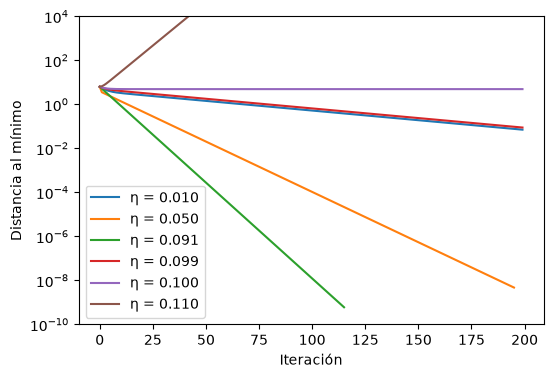

In [3]:
grad2 = lambda p: np.array([2 * (p[0] - 1), 20 * (p[1] + 2)])
minimo2 = np.array([1.0, -2.0])

pasos = [0.01, 0.05, 1 / 11, 0.099, 0.1, 0.11]
resultados = {}
fig, ax = plt.subplots(figsize=(6, 4))
for paso in pasos:
    x, it, tray = descenso(grad2, [5.0, 3.0], paso, max_iter=3000)
    errores = np.linalg.norm(tray - minimo2, axis=1)
    convergio = np.linalg.norm(grad2(x)) < 1e-8
    resultados[paso] = it if convergio else math.inf
    print(f"η = {paso:.4f}: {'converge en ' + str(it) + ' iteraciones' if convergio else 'no converge'} (error final {errores[-1]:.2g})")
    ax.semilogy(errores[:200], label=f"η = {paso:.3f}")
ax.set_xlabel("Iteración")
ax.set_ylabel("Distancia al mínimo")
ax.set_ylim(1e-10, 1e4)
ax.legend()
plt.show()

assert min(resultados, key=resultados.get) == 1 / 11
assert resultados[0.1] == resultados[0.11] == math.inf

## 3. Comprobar un gradiente

Un error en el gradiente estropea cualquier método. Para $f(x, y) = \sin(x)\, e^{y} + x^2 y$, escribir el gradiente analítico y compararlo en varios puntos aleatorios (semilla fija) con diferencias centradas $\frac{f(x + h e_i) - f(x - h e_i)}{2h}$, con `optimize.approx_fprime` y con `optimize.check_grad`. Mostrar también que un gradiente con un error de signo se detecta.

In [4]:
def f3(p):
    x, y = p
    return math.sin(x) * math.exp(y) + x**2 * y


def grad3(p):
    x, y = p
    return np.array([math.cos(x) * math.exp(y) + 2 * x * y, math.sin(x) * math.exp(y) + x**2])


def gradiente_numerico(f, p, h=1e-6):
    p = np.asarray(p, dtype=float)
    return np.array([(f(p + h * e) - f(p - h * e)) / (2 * h) for e in np.eye(len(p))])


rng = np.random.default_rng(37)
for p in rng.uniform(-2, 2, size=(5, 2)):
    centrado = gradiente_numerico(f3, p)
    assert np.allclose(grad3(p), centrado, atol=1e-6)
    assert np.allclose(grad3(p), optimize.approx_fprime(p, f3, 1e-7), atol=1e-4)
    assert optimize.check_grad(f3, grad3, p) < 1e-5

malo = lambda p: grad3(p) * np.array([1, -1])
p = np.array([0.5, 0.3])
print(f"check_grad correcto: {optimize.check_grad(f3, grad3, p):.1e}; con error de signo: {optimize.check_grad(f3, malo, p):.2f}")

check_grad correcto: 5.5e-09; con error de signo: 1.79


## 4. Descenso con momento

En $f(x, y) = \frac{1}{2}(x^2 + 100 y^2)$ el número de condición es $\kappa = L/\mu = 100$ y el descenso simple zigzaguea. El método de la bola pesada suma una fracción $\beta$ del paso anterior: $v \leftarrow \beta v - \eta \nabla f$, $x \leftarrow x + v$. Comparar las iteraciones del descenso simple con su paso óptimo $2/(L + \mu)$ y del momento con $\eta = \frac{4}{(\sqrt L + \sqrt \mu)^2}$ y $\beta = \left(\frac{\sqrt\kappa - 1}{\sqrt\kappa + 1}\right)^2$, y comprobar ambos mínimos con `minimize`.

In [5]:
mu, L = 1.0, 100.0
f4 = lambda p: 0.5 * (mu * p[0] ** 2 + L * p[1] ** 2)
grad4 = lambda p: np.array([mu * p[0], L * p[1]])
inicio = [10.0, 1.0]

x_simple, it_simple, _ = descenso(grad4, inicio, 2 / (L + mu))
eta = 4 / (math.sqrt(L) + math.sqrt(mu)) ** 2
beta = ((math.sqrt(L / mu) - 1) / (math.sqrt(L / mu) + 1)) ** 2
x_momento, it_momento, _ = descenso(grad4, inicio, eta, momento=beta)
referencia = optimize.minimize(f4, inicio, jac=grad4, method="BFGS")

print(f"Descenso simple: {it_simple} iteraciones")
print(f"Con momento (η = {eta:.4f}, β = {beta:.4f}): {it_momento} iteraciones")
print(f"minimize (BFGS): {referencia.x.round(8) + 0.0}")
assert it_momento * 3 < it_simple
for x in (x_simple, x_momento, referencia.x):
    assert np.allclose(x, 0, atol=1e-6)

Descenso simple: 1152 iteraciones
Con momento (η = 0.0331, β = 0.6694): 143 iteraciones
minimize (BFGS): [0. 0.]


## 5. Sección áurea

Una lata cilíndrica de 330 ml con radio $r$ (cm) tiene superficie $A(r) = 2\pi r^2 + \frac{2V}{r}$. Escribir `seccion_aurea(f, a, b, tol)`, que reduzca el intervalo $[a, b]$ en la razón $1/\varphi \approx 0{,}618$ en cada paso evaluando la función una sola vez por iteración. Calcular el radio que minimiza la superficie y compararlo con la solución exacta $r = \sqrt[3]{V / 2\pi}$ y con `minimize_scalar` (métodos `golden` y `bounded`). Contar las evaluaciones.

In [6]:
INV_PHI = (math.sqrt(5) - 1) / 2


def seccion_aurea(f, a, b, tol=1e-8):
    evaluaciones = 2
    c, d = b - INV_PHI * (b - a), a + INV_PHI * (b - a)
    fc, fd = f(c), f(d)
    while b - a > tol:
        if fc < fd:
            b, d, fd = d, c, fc
            c = b - INV_PHI * (b - a)
            fc = f(c)
        else:
            a, c, fc = c, d, fd
            d = a + INV_PHI * (b - a)
            fd = f(d)
        evaluaciones += 1
    return (a + b) / 2, evaluaciones


V = 330.0
superficie = lambda r: 2 * math.pi * r**2 + 2 * V / r
r_aurea, evaluaciones = seccion_aurea(superficie, 0.5, 10)
r_exacto = (V / (2 * math.pi)) ** (1 / 3)
r_golden = optimize.minimize_scalar(superficie, bracket=(0.5, 3, 10), method="golden").x
r_bounded = optimize.minimize_scalar(superficie, bounds=(0.5, 10), method="bounded", options={"xatol": 1e-9}).x
print(f"Sección áurea: r = {r_aurea:.6f} cm ({evaluaciones} evaluaciones); altura = {V / (math.pi * r_aurea**2):.4f} cm")
print(f"Exacto: {r_exacto:.6f}; golden: {r_golden:.6f}; bounded: {r_bounded:.6f}")
assert all(math.isclose(r, r_exacto, abs_tol=1e-6) for r in (r_aurea, r_golden, r_bounded))
assert evaluaciones == 2 + math.ceil(math.log(1e-8 / 9.5) / math.log(INV_PHI))

Sección áurea: r = 3.744939 cm (45 evaluaciones); altura = 7.4899 cm
Exacto: 3.744939; golden: 3.744938; bounded: 3.744939


## 6. Descenso con búsqueda en línea exacta

En lugar de un paso fijo, elegir en cada iteración el $\eta$ que minimiza $f(x - \eta \nabla f(x))$ con `seccion_aurea` en $[0, 1]$. En una cuadrática $f(x) = \frac{1}{2} x^\top A x$ ese paso tiene fórmula cerrada, $\eta = \frac{g^\top g}{g^\top A g}$: comprobar que coinciden en cada iteración. Contar las iteraciones sobre la función del ejercicio 4 y comprobar que dos direcciones consecutivas son perpendiculares (el zigzag).

In [7]:
A = np.diag([mu, L])
x = np.array(inicio)
iteraciones = 0
g_anterior = None
while np.linalg.norm(g := A @ x) > 1e-8:
    paso, _ = seccion_aurea(lambda t: f4(x - t * g), 0, 1, tol=1e-12)
    assert math.isclose(paso, (g @ g) / (g @ A @ g), rel_tol=1e-6)
    if g_anterior is not None:
        assert abs(g @ g_anterior) < 1e-6 * np.linalg.norm(g) * np.linalg.norm(g_anterior)
    x, g_anterior = x - paso * g, g
    iteraciones += 1
print(f"Búsqueda en línea exacta: {iteraciones} iteraciones (paso fijo óptimo: {it_simple}); distancia al mínimo {np.linalg.norm(x):.1e}")
assert np.allclose(x, 0, atol=1e-7)

Búsqueda en línea exacta: 61 iteraciones (paso fijo óptimo: 1152); distancia al mínimo 5.0e-09


## 7. La función de Rosenbrock

La función $f(x, y) = (1 - x)^2 + 100(y - x^2)^2$ tiene el mínimo en $(1, 1)$ al fondo de un valle estrecho y curvo. Minimizarla desde $(-1{,}2;\ 1)$ con descenso simple y con momento (paso $10^{-3}$, $\beta = 0{,}9$, tolerancia $10^{-6}$) y con `minimize` (BFGS). Comprobar el gradiente con `optimize.rosen_der` y comparar el número de iteraciones de los tres.

In [8]:
def rosen(p):
    x, y = p
    return (1 - x) ** 2 + 100 * (y - x**2) ** 2


def grad_rosen(p):
    x, y = p
    return np.array([-2 * (1 - x) - 400 * x * (y - x**2), 200 * (y - x**2)])


for p in np.random.default_rng(38).uniform(-2, 2, size=(4, 2)):
    assert math.isclose(rosen(p), optimize.rosen(p))
    assert np.allclose(grad_rosen(p), optimize.rosen_der(p))

inicio_r = [-1.2, 1.0]
x_s, it_s, _ = descenso(grad_rosen, inicio_r, 1e-3, tol=1e-6, max_iter=100_000)
x_m, it_m, _ = descenso(grad_rosen, inicio_r, 1e-3, momento=0.9, tol=1e-6, max_iter=100_000)
bfgs = optimize.minimize(rosen, inicio_r, jac=grad_rosen, method="BFGS", options={"gtol": 1e-6})
print(f"{'método':<16} {'iteraciones':>11}  x")
for nombre, x, it in [("simple", x_s, it_s), ("momento", x_m, it_m), ("BFGS", bfgs.x, bfgs.nit)]:
    print(f"{nombre:<16} {it:>11}  {x.round(6)}")
    assert np.allclose(x, [1, 1], atol=1e-4)
assert bfgs.nit < it_m < it_s

método           iteraciones  x
simple                 32076  [0.999999 0.999998]
momento                 3020  [0.999999 0.999998]
BFGS                      33  [1. 1.]


## 8. Método de Newton multivariante

El método de Newton usa la hessiana: $x \leftarrow x - H(x)^{-1} \nabla f(x)$, resolviendo el sistema $H\,d = \nabla f$ en lugar de invertir. Aplicarlo a Rosenbrock desde $(-1{,}2;\ 1)$, comprobar la hessiana con `optimize.rosen_hess`, mostrar el error en cada iteración (la convergencia cuadrática duplica los decimales correctos al final) y comparar con `minimize(method="Newton-CG")`.

In [9]:
def hess_rosen(p):
    x, y = p
    return np.array([[2 - 400 * (y - x**2) + 800 * x**2, -400 * x], [-400 * x, 200]])


assert np.allclose(hess_rosen([0.3, -0.7]), optimize.rosen_hess([0.3, -0.7]))

x = np.array(inicio_r)
for k in range(1, 30):
    x = x - np.linalg.solve(hess_rosen(x), grad_rosen(x))
    error = np.linalg.norm(x - 1)
    print(f"iteración {k}: error {error:.2e}")
    if error < 1e-12:
        break
newton_cg = optimize.minimize(rosen, inicio_r, jac=grad_rosen, hess=hess_rosen, method="Newton-CG", options={"xtol": 1e-12})
print(f"Newton a mano: {k} iteraciones; Newton-CG: {newton_cg.nit} iteraciones, x = {newton_cg.x.round(8)}")
assert np.allclose(x, 1) and np.allclose(newton_cg.x, 1, atol=1e-6)

iteración 1: error 2.21e+00
iteración 2: error 4.18e+00
iteración 3: error 4.80e-01
iteración 4: error 5.60e-02
iteración 5: error 9.62e-06
iteración 6: error 1.85e-11
iteración 7: error 0.00e+00
Newton a mano: 7 iteraciones; Newton-CG: 86 iteraciones, x = [1. 1.]


## 9. Varios mínimos locales

La función de Himmelblau, $f(x, y) = (x^2 + y - 11)^2 + (x + y^2 - 7)^2$, tiene cuatro mínimos globales con $f = 0$. Lanzar `minimize` desde una rejilla de 25 puntos iniciales en $[-5, 5]^2$, agrupar los mínimos encontrados redondeando y comprobar que son cuatro, que todos valen 0 y que uno es exactamente $(3, 2)$. Refinar cada uno con el método de Newton usando la hessiana numérica (diferencias del gradiente) y comprobar que no se mueve.

In [10]:
def himmelblau(p):
    x, y = p
    return (x**2 + y - 11) ** 2 + (x + y**2 - 7) ** 2


def grad_himmelblau(p):
    x, y = p
    a, b = x**2 + y - 11, x + y**2 - 7
    return np.array([4 * x * a + 2 * b, 2 * a + 4 * y * b])


def hessiana_numerica(grad, p, h=1e-6):
    return np.array([(grad(p + h * e) - grad(p - h * e)) / (2 * h) for e in np.eye(len(p))])


minimos = set()
for x0 in np.linspace(-5, 5, 5):
    for y0 in np.linspace(-5, 5, 5):
        res = optimize.minimize(himmelblau, [x0, y0], jac=grad_himmelblau, method="BFGS", options={"gtol": 1e-10})
        minimos.add(tuple(np.round(res.x, 5)))

for m in sorted(minimos):
    p = np.array(m)
    for _ in range(3):
        p = p - np.linalg.solve(hessiana_numerica(grad_himmelblau, p), grad_himmelblau(p))
    print(f"({p[0]:+.6f}, {p[1]:+.6f})  f = {himmelblau(p):.1e}")
    assert himmelblau(p) < 1e-15 and np.allclose(p, m, atol=1e-4)
assert len(minimos) == 4 and (3.0, 2.0) in minimos

(-3.779310, -3.283186)  f = 7.9e-31
(-2.805118, +3.131313)  f = 7.9e-31
(+3.000000, +2.000000)  f = 0.0e+00
(+3.584428, -1.848127)  f = 0.0e+00


## 10. Mínimos cuadrados: ecuaciones normales

Simular (semilla fija) la temperatura media de 15 estaciones de Tenerife entre el nivel del mar y 3 700 m como $T = 21 - 6{,}5\,h + \varepsilon$ ($h$ en km, ruido normal de desviación 0,8 °C). Ajustar la recta que minimiza $\lVert X\beta - y\rVert^2$ resolviendo las ecuaciones normales $X^\top X \beta = X^\top y$ y compararla con `np.linalg.lstsq`, `np.polyfit` y `minimize` sobre la suma de cuadrados. Estimar la temperatura en la cumbre del Teide (3,715 km).

In [11]:
rng = np.random.default_rng(39)
h = np.sort(rng.uniform(0, 3.7, 15))
T = 21 - 6.5 * h + rng.normal(0, 0.8, 15)
X = np.column_stack([np.ones_like(h), h])

beta_normales = np.linalg.solve(X.T @ X, X.T @ T)
beta_lstsq, *_ = np.linalg.lstsq(X, T, rcond=None)
beta_polyfit = np.polyfit(h, T, 1)[::-1]
beta_minimize = optimize.minimize(lambda b: np.sum((X @ b - T) ** 2), [0, 0]).x

print(f"T = {beta_normales[0]:.3f} {beta_normales[1]:+.3f}·h; en el Teide: {beta_normales @ [1, 3.715]:.1f} °C")
for b in (beta_lstsq, beta_polyfit, beta_minimize):
    assert np.allclose(b, beta_normales, atol=1e-5)
residuos = T - X @ beta_normales
assert np.allclose(X.T @ residuos, 0, atol=1e-10)  # el residuo es ortogonal a las columnas

T = 21.140 -6.626·h; en el Teide: -3.5 °C


## 11. Cuándo fallan las ecuaciones normales

El número de condición de $X^\top X$ es el cuadrado del de $X$, así que las ecuaciones normales pierden el doble de cifras. Con un polinomio de grado 9 en $[0, 1]$ y datos exactos $y = X c$ (coeficientes conocidos), comparar el error al recuperar $c$ con las ecuaciones normales y con `lstsq` (que usa la SVD). Comprobar que $\kappa(X^\top X) \approx \kappa(X)^2$.

In [12]:
x = np.linspace(0, 1, 50)
X = np.vander(x, 10, increasing=True)
c = np.arange(1, 11, dtype=float)
y = X @ c

kappa = np.linalg.cond(X)
error_normales = np.linalg.norm(np.linalg.solve(X.T @ X, X.T @ y) - c) / np.linalg.norm(c)
error_lstsq = np.linalg.norm(np.linalg.lstsq(X, y, rcond=None)[0] - c) / np.linalg.norm(c)
print(f"κ(X) = {kappa:.1e}, κ(XᵀX) = {np.linalg.cond(X.T @ X):.1e}")
print(f"Error relativo: ecuaciones normales {error_normales:.1e}, lstsq {error_lstsq:.1e}")
assert math.isclose(math.log10(np.linalg.cond(X.T @ X)), 2 * math.log10(kappa), rel_tol=0.1)
assert error_lstsq * 100 < error_normales

κ(X) = 3.6e+06, κ(XᵀX) = 1.3e+13
Error relativo: ecuaciones normales 1.8e-04, lstsq 4.9e-11


## 12. Mínimos cuadrados no lineales

Un café se enfría según $T(t) = T_a + (T_0 - T_a)\,e^{-kt}$. Simular 20 medidas en 30 minutos (semilla fija, $T_a = 22$, $T_0 = 85$, $k = 0{,}07$, ruido de 0,5 °C) y estimar los tres parámetros con `optimize.curve_fit`. Compararlo con una linealización: si se conoce $T_a$, $\ln(T - T_a) = \ln(T_0 - T_a) - kt$ es una recta. Comprobar que ambas estimaciones de $k$ están cerca de 0,07 y que `curve_fit` deja menos suma de cuadrados que la linealización.

In [13]:
rng = np.random.default_rng(40)
t = np.linspace(0, 30, 20)
modelo = lambda t, Ta, T0, k: Ta + (T0 - Ta) * np.exp(-k * t)
medidas = modelo(t, 22, 85, 0.07) + rng.normal(0, 0.5, t.size)

(Ta, T0, k), _ = optimize.curve_fit(modelo, t, medidas, p0=[20, 80, 0.1])
pendiente, ordenada = np.polyfit(t, np.log(medidas - 22), 1)
k_lineal, T0_lineal = -pendiente, 22 + math.exp(ordenada)

sc = lambda *p: float(np.sum((modelo(t, *p) - medidas) ** 2))
print(f"curve_fit:     Ta = {Ta:.2f}, T0 = {T0:.2f}, k = {k:.4f}, SC = {sc(Ta, T0, k):.2f}")
print(f"linealización: Ta = 22 (fija), T0 = {T0_lineal:.2f}, k = {k_lineal:.4f}, SC = {sc(22, T0_lineal, k_lineal):.2f}")
assert abs(k - 0.07) < 0.01 and abs(k_lineal - 0.07) < 0.01
assert sc(Ta, T0, k) <= sc(22, T0_lineal, k_lineal)

curve_fit:     Ta = 21.73, T0 = 84.49, k = 0.0692, SC = 2.35
linealización: Ta = 22 (fija), T0 = 84.58, k = 0.0700, SC = 2.40


## 13. Multiplicadores de Lagrange

Una quesería produce $f(x, y) = x^{0{,}6} y^{0{,}4}$ unidades con $x$ horas de trabajo (20 € la hora) e $y$ litros de leche (10 € el litro), y dispone de 1 000 €. Maximizar la producción con la restricción $20x + 10y = 1000$: plantear las condiciones $\nabla f = \lambda \nabla g$, $g = 0$ y resolverlas con `optimize.root`, compararlo con la solución exacta ($x = 0{,}6 \cdot 1000/20$, $y = 0{,}4 \cdot 1000/10$) y con `minimize` con SLSQP. Comprobar que $\lambda$ es lo que aumenta la producción máxima por cada euro más de presupuesto.

In [14]:
def produccion(p):
    x, y = p
    return x**0.6 * y**0.4


def optimo(presupuesto):
    restriccion = {"type": "eq", "fun": lambda p: 20 * p[0] + 10 * p[1] - presupuesto}
    res = optimize.minimize(lambda p: -produccion(p), [10, 10], method="SLSQP", constraints=[restriccion],
                            bounds=[(1e-6, None)] * 2, options={"ftol": 1e-12})
    return res.x


def lagrange(v):
    x, y, lam = v
    return [0.6 * x**-0.4 * y**0.4 - 20 * lam, 0.4 * x**0.6 * y**-0.6 - 10 * lam, 20 * x + 10 * y - 1000]


x, y, lam = optimize.root(lagrange, [10, 10, 0.1]).x
slsqp = optimo(1000)
print(f"Lagrange: x = {x:.4f}, y = {y:.4f}, λ = {lam:.5f}; SLSQP: {slsqp.round(4)}")
assert np.allclose([x, y], [30, 40]) and np.allclose(slsqp, [30, 40], atol=1e-3)

ganancia = produccion(optimo(1001)) - produccion(optimo(1000))
print(f"Producción extra con 1 € más: {ganancia:.5f} (λ = {lam:.5f})")
assert math.isclose(ganancia, lam, rel_tol=1e-3)

Lagrange: x = 30.0000, y = 40.0000, λ = 0.03366; SLSQP: [30. 40.]
Producción extra con 1 € más: 0.03366 (λ = 0.03366)


## 14. Restricciones de desigualdad y KKT

Encontrar el punto más cercano a $(3, 2)$ dentro de la región $x + y \le 4$, $x \ge 0$, $y \ge 0$, minimizando $(x - 3)^2 + (y - 2)^2$ con SLSQP. Comprobar las condiciones de Karush-Kuhn-Tucker en la solución $(2{,}5;\ 1{,}5)$: solo la primera restricción está activa y existe $\mu \ge 0$ con $\nabla f + \mu \nabla g = 0$. Verificarlo también con una búsqueda por fuerza bruta en una rejilla de paso 0,005.

In [15]:
objetivo = lambda p: (p[0] - 3) ** 2 + (p[1] - 2) ** 2
res = optimize.minimize(objetivo, [0, 0], method="SLSQP", bounds=[(0, None), (0, None)],
                        constraints=[{"type": "ineq", "fun": lambda p: 4 - p[0] - p[1]}])
print(f"SLSQP: {res.x.round(6)}, distancia {math.sqrt(res.fun):.6f}")

grad_f = np.array([2 * (res.x[0] - 3), 2 * (res.x[1] - 2)])
grad_g = np.array([1.0, 1.0])
mu_kkt = -grad_f[0] / grad_g[0]
print(f"μ = {mu_kkt:.6f}; ∇f + μ∇g = {(grad_f + mu_kkt * grad_g).round(8)}")
assert mu_kkt > 0 and np.allclose(grad_f + mu_kkt * grad_g, 0, atol=1e-6)
assert math.isclose(res.x.sum(), 4, abs_tol=1e-8) and (res.x > 0).all()

xs, ys = np.meshgrid(np.arange(0, 4.001, 0.005), np.arange(0, 4.001, 0.005))
factibles = xs + ys <= 4 + 1e-12
valores = np.where(factibles, (xs - 3) ** 2 + (ys - 2) ** 2, np.inf)
i = np.unravel_index(valores.argmin(), valores.shape)
print(f"Rejilla: ({xs[i]:.3f}, {ys[i]:.3f})")
assert np.allclose(res.x, [2.5, 1.5], atol=1e-6) and np.allclose([xs[i], ys[i]], [2.5, 1.5])

SLSQP: [2.5 1.5], distancia 0.707107
μ = 1.000000; ∇f + μ∇g = [0. 0.]
Rejilla: (2.500, 1.500)
